# 20 概率入门(Fundamentals of Probability)

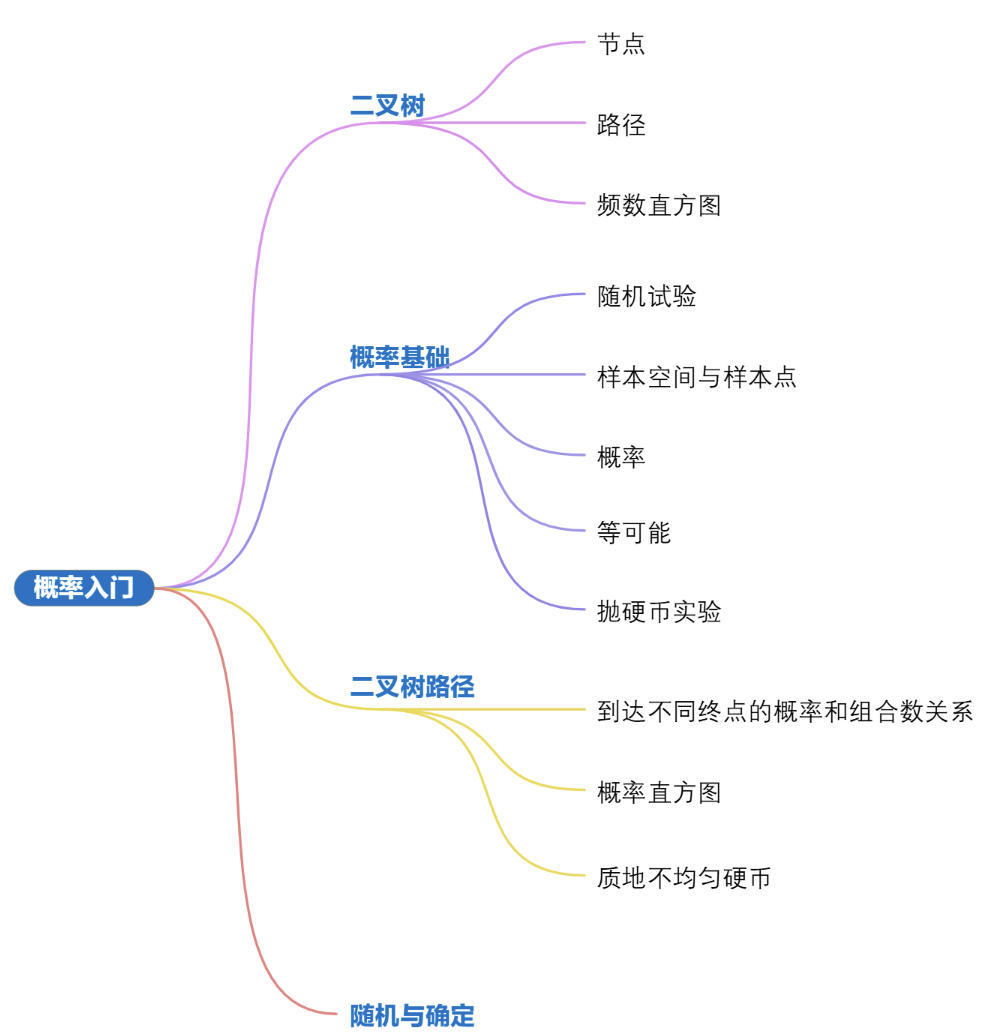

# 20.1 概率简史：出身赌场

<font color="blue">略</font>

## 20.2 二叉树：一生二、二生三

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import binom
from scipy.stats import binom as binom_dist

### 二叉树原理

In [15]:
def build_binomial_tree(ax, n):
    """
    绘制二项树
    参数:
    - ax: 子图对象
    - n: 树的层数
    """
    for i in np.arange(n):
        Nodes_y = np.linspace(-i, i, i+1)
        B_y = np.concatenate((Nodes_y+1, Nodes_y-1))
        B_x = np.zeros_like(B_y) + i  + 1
        A_y = np.concatenate((Nodes_y, Nodes_y))
        A_x = np.zeros_like(A_y) + i
        x_AB = np.stack((A_x, B_x))
        y_AB = np.stack((A_y, B_y))
        ax.plot(x_AB, y_AB, "o-", color="#92d050",
               markerfacecolor="#0099FF",
               markeredgecolor=None)
        
        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)
        ax.set_xlim(0, n)
        ax.set_ylim(-n - 1, n + 1)
        ax.set_title("Binomial Tree")
        ax.grid(False)

当 $n=1$ 时，二叉树叫做<font color="blue">一步二叉树</font>(one-stepbinomialtree)。也就是说，登山者从初始点出发，只有两个路径到达两个不同终点。
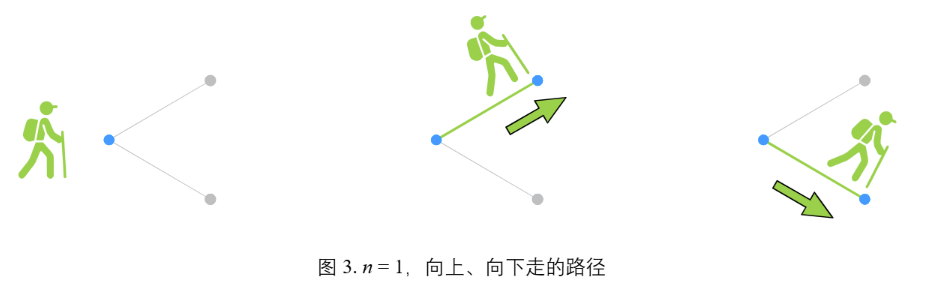

$n=2$ 时，二叉树为<font color="blue">两步二叉树</font>(two-step binomial tree)。从起点到终点，一共有 4 条路径，二项式系数 1、2、1 则相当于到达对应 $A$、$B$、$C$终点的可能路径数量。
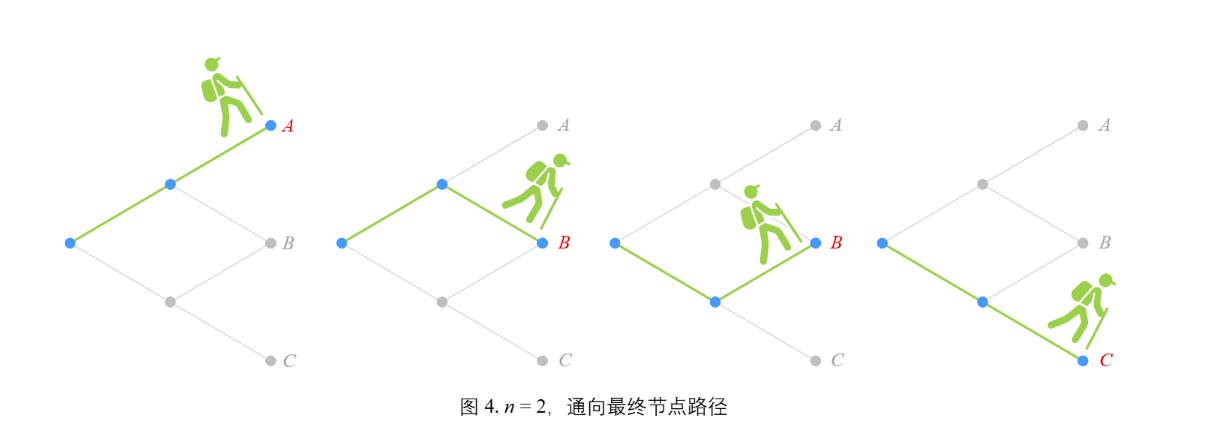

当二叉树的层数不断增多，到达终点的路径的数量呈现指数增长趋势。

### 组合数

利用<font color="blue">水平条形图</font>(horizontal bargraph)可视化二叉树路径数。

In [18]:
def plot_binomial_coefficients(ax, n):
    """
    绘制二项式系数柱状图
    参数:
    - ax: 子图对象
    - n: 树的层数(实验次数)
    """

    degrees = np.linspace(n, 0, n + 1)
    poly_coeffs = binom(n, degrees) 
    locations = np.linspace(-n, n, n + 1)
    ax.barh(locations, poly_coeffs, align="center", color="blue")
    
    for i, (loc, coeff) in enumerate(zip(locations, poly_coeffs)):
        ax.text(coeff + poly_coeffs.max() * 0.1, loc, str(int(coeff)))
    
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.set_ylim(-n - 1, n + 1)
    ax.set_title("Binomial Coefficients")
    ax.grid(False)

$n=3$ 时，到达二叉树终点节点的路径分别有1、3、3、1条，总共有 8 条路径，写成组合数:
$$
C^0_3+C^1_3+C^2_3+C^3_3=1+3+3+1=8=2^3
$$

$C^0_3$ 可以理解为，3 次决策中 0 次向下；$C^1_3$ 可以理解为，3 次决策中 1 次向下；$C^2_3$ 可以理解为，3 次决策中 2 次向下；$C^3_3$ 可以理解为，3 次决策中 3 次向下。

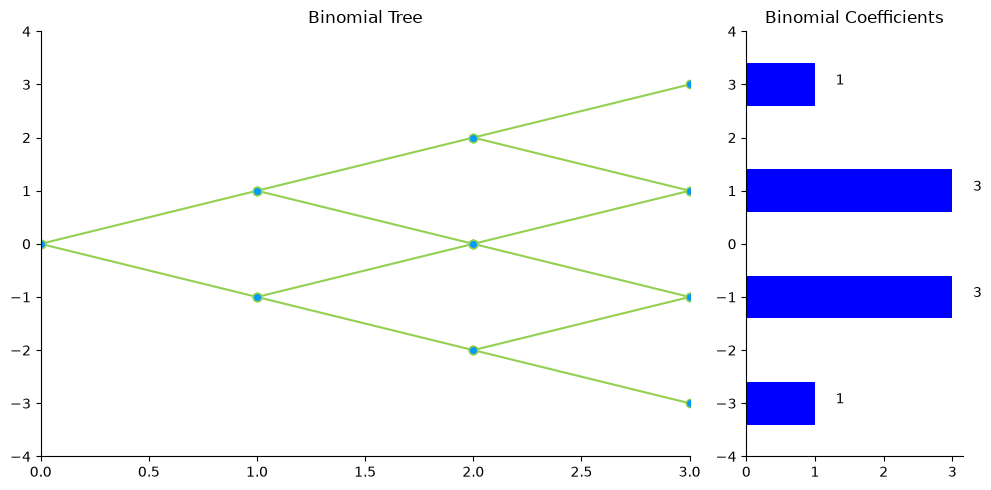

In [20]:
n = 3
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios":[3, 1]})
build_binomial_tree(axes[0], n)
plot_binomial_coefficients(axes[1], n)
plt.tight_layout()
plt.show()

$n=4$ 时，到达二叉树终点节点的路径分别有1、4、6、4、1条，总共有16条路径：
$$
C^0_4+C^1_4+C^2_4+C^3_4+C^4_4=1+4+6+4+1=16=24
$$

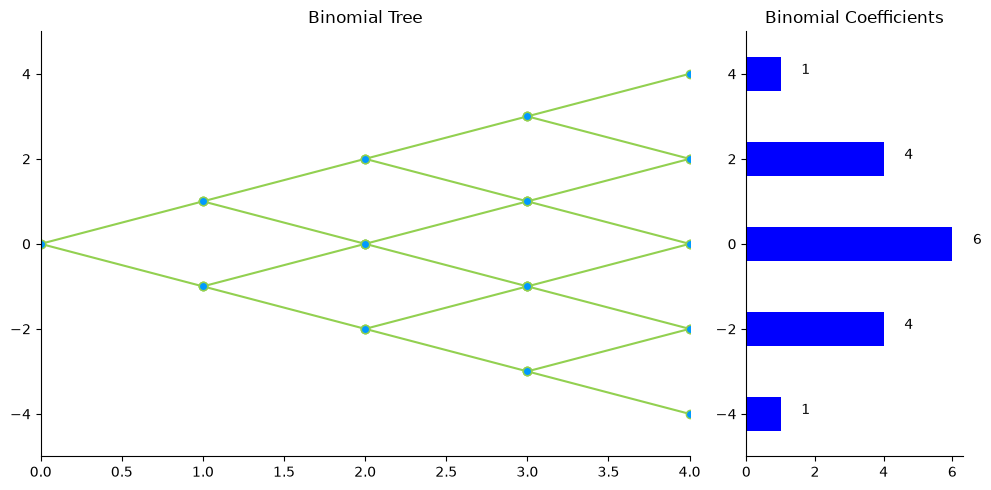

In [21]:
n = 4
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios":[3, 1]})
build_binomial_tree(axes[0], n)
plot_binomial_coefficients(axes[1], n)
plt.tight_layout()
plt.show()

$n=5$ 时，登山者有5次“二选一”决策，到达二叉树终点节点的路径分别有1、5、10、10、5、1条，总共有32条路径:
$$
C^0_5+C^1_5+C^2_5+C^3_5+C^4_5+C^5_5=1+5+10+10+5+1=32=2^5
$$

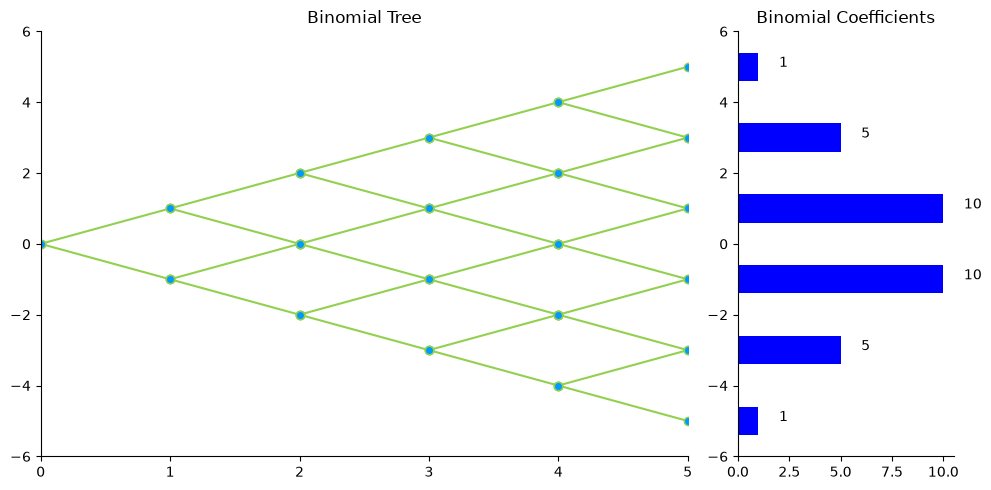

In [22]:
n = 5
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios":[3, 1]})
build_binomial_tree(axes[0], n)
plot_binomial_coefficients(axes[1], n)
plt.tight_layout()
plt.show()

从概率统计角度，右侧的直方图常被称作频数直方图(frequency histogram)。频数也称次数，是对总数据按某种标准进行分组，统计出各个组内含个体的个数。

## 20.3 抛硬币：正反面概率

### 确定与随机

在自然界和社会实践活动中，人类遇到的各种现象可分为两大类:确定现象，随机现象。

随机现象的准确定义是:在一定条件下，出现的可能结果不止一个，事前无法确切知道哪一个结果一定会出现，但大量重复试验中其结果又具有统计规律的现象称为随机现象。

### 随机实验

<font color="blue">随机试验</font>(random experiment)是在相同条件下对某随机现象进行的大量重复观测。随机试验需要满足三个条件:

- a)可重复，在相同条件下试验可以重复进行；
- b)结果集合明确，每次试验的可能结果不止一个，并且能事先明确试验的所有可能结果；
- c)单次试验结果不确定，进行一次试验之前不能确定哪一个结果会出现，但必然出现结果集合中的一个。

给定一个随机试验，所有的结果构成的集合为样本空间 $\Omega$。样本空间 $\Omega$ 中的每一个元素为一个样本点。

### 概率

<font color="blue">概率</font>(probability)反映随机事件出现的可能性大小。

给定任意一个事件 $A$，$\mathrm{Pr}(A)$为事件 $A$ 发生的概率(the probability of event A occurring)。

对于任意事件 $A$，$A$ 发生的概率满足:
$$
\mathbf{Pr}(\Omega) \ge 0
$$

整个样本空间的概率为 1，即，
$$
\mathrm{Pr}(\Omega)=1
$$

空集不包含任何样本点，也称作不可能事件，因此对应的概率为 0，即:
$$
\mathrm{Pr}(\varnothing)=0
$$

### 等可能

等可能性是指设一个试验的所有可能发生的结果有n个，它们都是随机事件，每次试验有且只有其中的一个结果出现。

### 抛硬币

举最简单的例子，抛一枚硬币，1 代表落地结果正面、0 代表反面。抛一枚硬币的可能结果样本空间 $\Omega$ 为:
$$
\Omega = \{0, 1\}
$$

连续抛 100 枚硬币，并记录每次硬币正(1)、反面(0)结果。可以发现，随着抛硬币的次数不断增多，硬币正反面平均值愈靠近 1/2。

In [23]:
import numpy as np
import matplotlib.pyplot as plt

In [24]:
p = plt.rcParams
p["ytick.minor.visible"] = True  # 显示 y 轴的小刻度
p["xtick.minor.visible"] = True  # 显示 x 轴的小刻度
p["axes.grid"] = True
p["grid.color"] = "0.5"
p["grid.linewidth"] = 0.5

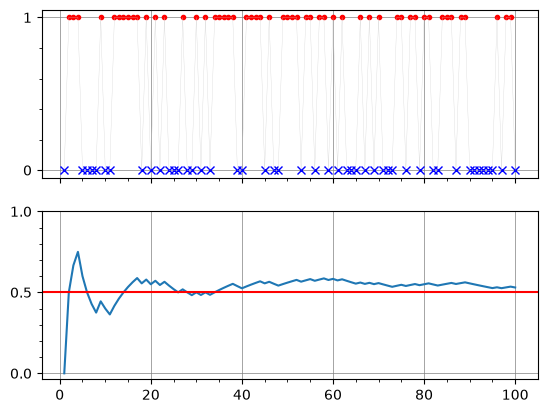

In [28]:
# 抛硬币实验
num_toss = 100
toss = np.random.randint(low=0, high=2, size=(num_toss, 1))

up = (toss == 1)

iteration = np.arange(1, num_toss + 1)

fig, axs = plt.subplots(2, 1, sharex = True)

# 可视化1：抛掷结果散点图
axs[0].plot(iteration[up.flatten()], toss[up], color="r", marker=".", linestyle="None")
axs[0].plot(iteration[~up.flatten()], toss[~up], color="b", marker="x", linestyle="None")
axs[0].plot(iteration, toss, color="0.8", lw=0.2)
axs[0].set_yticks([0, 1])

# 可视化2：累计均值曲线
cum_mean = np.cumsum(toss) / iteration

axs[1].plot(iteration, cum_mean)
axs[1].axhline(y=0.5, color="r")
axs[1].set_yticks([0, 0.5, 1])

## 20.4 聊聊概率：向上还是向下

### 概率直方图

这种直方图被称作<font color="blue">概率直方图</font>(probability histogram)。频数直方图和概率直方图可以很容易相互转化。注意，直方图可以展示频数、概率值、概率密度值。概率密度积分后得到概率值。

In [29]:
def plot_binomial_probabilities(ax, n, p):
    """
    绘制二项式系数柱状图
    参数:
    - ax: 子图对象
    - n: 树的层数(实验次数)
    - p: 成功的概率
    """

    x = np.arange(0, n + 1)
    p_x = binom_dist.pmf(x, n, p)
    locations = np.linspace(-n, n, n + 1)
    ax.barh(locations, p_x, align="center", color="blue")
    
    for i, (loc, prob) in enumerate(zip(locations, p_x)):
        ax.text(prob + p_x.max() * 0.1, loc, f"{prob:4f}")
    
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.set_ylim(-n - 1, n + 1)
    ax.set_title("Binomial Probabilities")
    ax.grid(False)

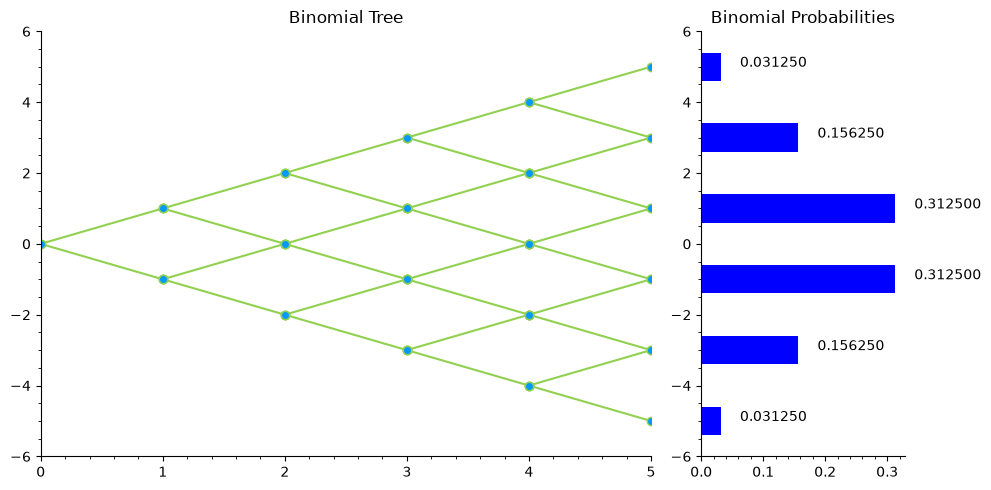

In [30]:
n = 5
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [3, 1]})
build_binomial_tree(axes[0], n)
plot_binomial_probabilities(axes[1], n, 0.5)
plt.tight_layout()
plt.show()

## 20.5 一枚质地不均匀的硬币

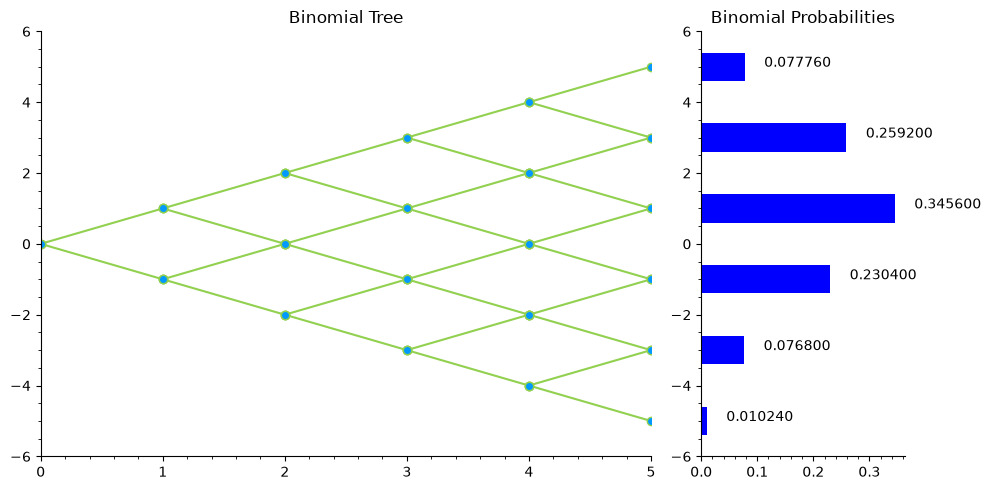

In [31]:
n = 5
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [3, 1]})
build_binomial_tree(axes[0], n)
plot_binomial_probabilities(axes[1], n, 0.6)
plt.tight_layout()
plt.show()

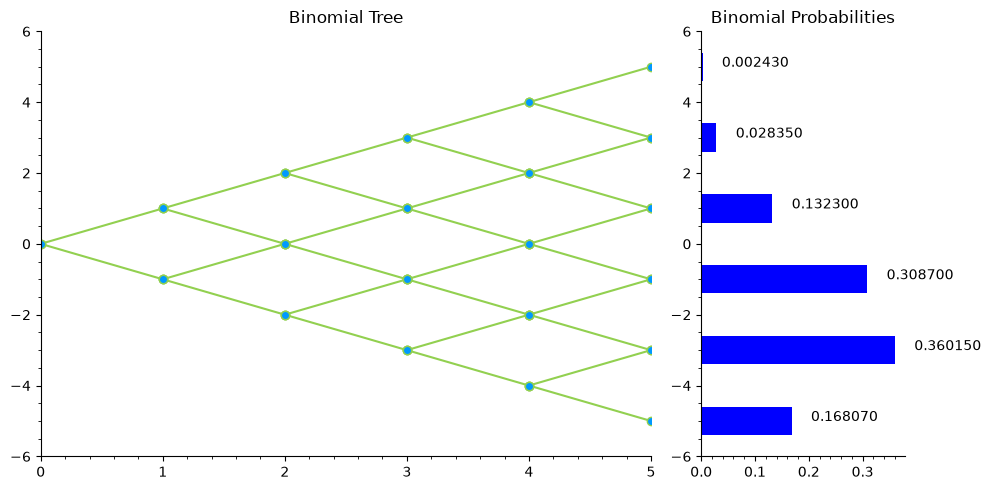

In [32]:
n = 5
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [3, 1]})
build_binomial_tree(axes[0], n)
plot_binomial_probabilities(axes[1], n, 0.3)
plt.tight_layout()
plt.show()

## 20.6 随机中有规律

在给定的二叉树网格中，登山者在不同节点“随机”确定向上走、向下走，得到的结果就是一种<font color="blue">随机漫步</font>(random walk)。

随着路径数量增多，我们似乎可以预感，到达终点时登山者在中间的可能性会高于两端。

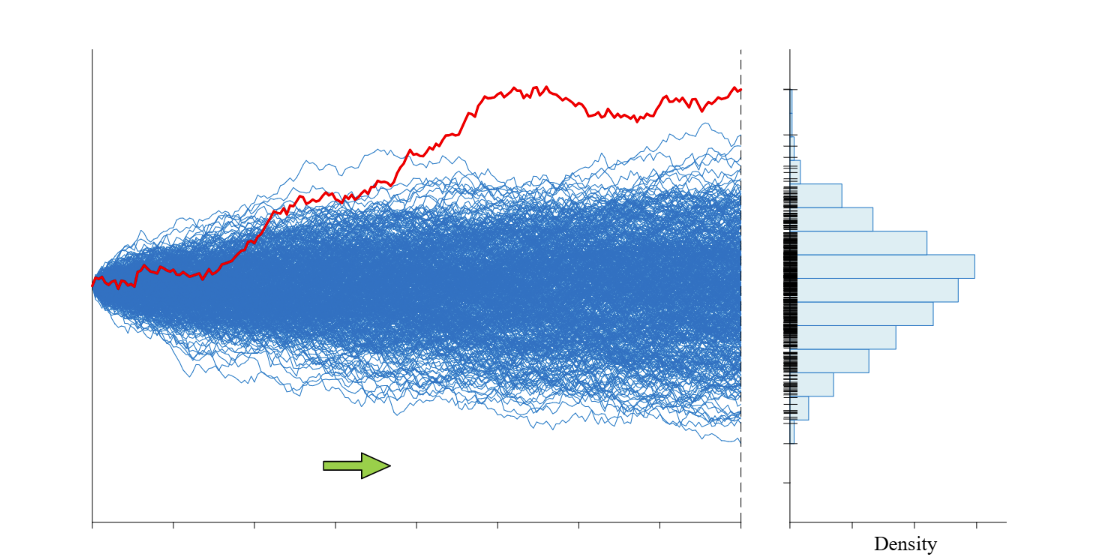